https://support.minitab.com/ko-kr/minitab/help-and-how-to/statistics/basic-statistics/how-to/correlation/interpret-the-results/all-statistics-and-graphs/

https://support.minitab.com/ko-kr/minitab/help-and-how-to/statistics/basic-statistics/how-to/correlation/methods-and-formulas/methods-and-formulas/

In [1]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
from project_manager import read_json_to_dict

In [41]:
# number = 2054854564.5121
number = 85134731138.48552
if isinstance(number, int):
    print(f"{number:,}")
elif isinstance(number, float):
    if (number < 0.0001) | (number > 1_000_000):
        print(f"{number:.2e}")
    else:
        print(f"{number:,.2f}")

8.51e+10


In [194]:
%matplotlib inline

In [195]:
project_dir = r'C:\Users\10007166\insightmaker_project\Dummy Test'

In [196]:
data_path = os.path.join(project_dir, 'data.pkl')
column_info_path = os.path.join(project_dir, 'column_info.json')
df = pd.read_pickle(data_path)
col_infos = read_json_to_dict(column_info_path)

In [197]:
# 수치형 변수 간 상관계수 - 피어슨/스피어만
from typing import List, Dict
from itertools import combinations
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr

In [198]:
def coefficient_confidence_interval(n: int, r: float, corr_method: str='pearson'):
    """ 상관 계수 신뢰 구간

    Args:
        n (int): 관측치 수
        r (float): 표본 상관 계수 추정치
        corr_method (str, optional): 상관 계수 Type. Defaults to 'pearson'.
    """
    z_base, z_diff, z_025 = 0, 0, 1.96
    if corr_method == 'pearson':
        z_base = 0.5*(math.log(1+r)-math.log(1-r))
        z_diff = z_025/math.sqrt(n-3)
    else:
        se = math.sqrt((1+math.pow(r,2)/2)/(n-3))
        z_base = 0.5*(math.log(1+r)-math.log(1-r))
        z_diff = z_025*se
    z_l, z_u = z_base - z_diff, z_base + z_diff
    lower = (math.exp(2*z_l)-1)/(math.exp(2*z_l)+1)
    upper = (math.exp(2*z_u)-1)/(math.exp(2*z_u)+1)
    return lower, upper

def judge_correlation_level(coeff: float):
    """ 상관 관계 정도 판정

    Args:
        coeff (float): 상관 계수
    """
    if -1<=coeff<-0.7:
        return '강한 음의 상관관계'
    elif -0.7<=coeff<-0.3:
        return '약한 음의 상관관계'
    elif -0.3<=coeff<0.3:
        return '상관관계 없음'
    elif 0.3<=coeff<0.7:
        return '약한 양의 상관관계'
    elif 0.7<=coeff<=1.0:
        return '강한 양의 상관관계'
    return None

In [199]:
def correlation_detail_info(df_sample: pd.DataFrame, columns: List[str], corr_method: str) -> List[Dict[str, object]]:
    """ 상관 관계 상세 분석

    Args:
        df_sample (pd.DataFrame): 샘플 데이터
        columns (List[str]): 변수 리스트
        corr_method (str): 상관 계수 Type

    Returns:
        List[Dict[str, object]]: 결과
    """
    corr_result = []
    for col1, col2 in combinations(columns, 2):
        sample = df_sample[[col1, col2]].dropna()
        n = len(sample)
        if n<4:
            corr_result.append(
                {
                    'Column1': str(col1),
                    'Column2': str(col2),
                    'SampleCount': n,
                    'Coefficient': None,
                    'ConfidenceIntervalLower': None,
                    'ConfidenceIntervalUpper': None,
                    'PValue': None,
                    'CorrelationLevel': None
                }
            )
        corr, p_val = None, None
        if corr_method == 'pearson':
            corr, p_val = pearsonr(sample[col1], sample[col2])
        else:
            corr, p_val = spearmanr(sample[col1], sample[col2])
        ci_l, ci_u = coefficient_confidence_interval(n, corr, corr_method)
        level = judge_correlation_level(corr)
        corr_result.append(
            {
                'Column1': str(col1),
                'Column2': str(col2),
                'SampleCount': n,
                # 'Coefficient': float(corr),
                'Coefficient': 0.8,
                'ConfidenceIntervalLower': float(ci_l),
                'ConfidenceIntervalUpper': float(ci_u),
                'PValue': float(p_val),
                'CorrelationLevel': level
            }
        )
    return corr_result

In [200]:
num_cols = [col for col in col_infos if (col['ColumnType']=='Numerical') and (col['ColumnChar']!='DateTime')]
cat_cols = [col for col in col_infos if col['ColumnChar']=='Ordinal']
columns = np.random.choice(num_cols + cat_cols, size=5, replace=False)

df_sample = df[[col['Column'] for col in columns]].copy(deep=True)
ordinals = [col['Column'] for col in columns if col['ColumnChar']=='Ordinal']
for ord_col in ordinals:
    df_sample[ord_col] = df_sample[ord_col].cat.codes

corr_method = 'spearman' if len(ordinals)>0 else str(np.random.choice(['pearson', 'sperman'], size=1)[0])

print([col['Column'] for col in columns])
print(f'상관 계수 Type: {corr_method}')
print(f"순서형 변수 포함 여부: {len(ordinals)>0} {','.join([col for col in ordinals])}")

['column8', 'column6', 'column10', 'column3', 'column17']
상관 계수 Type: spearman
순서형 변수 포함 여부: True column10,column3


In [201]:
corr_result = correlation_detail_info(df_sample, [col['Column'] for col in columns], corr_method)
pd.DataFrame(corr_result)

,Column1,Column2,SampleCount,Coefficient,ConfidenceIntervalLower,ConfidenceIntervalUpper,PValue,CorrelationLevel
0,column8,column6,500,0.8,-0.170625,0.003836,0.060411,상관관계 없음
1,column8,column10,500,0.8,-0.163373,0.011243,0.086854,상관관계 없음
2,column8,column3,500,0.8,-0.057576,0.117688,0.499207,상관관계 없음
3,column8,column17,500,0.8,-0.103548,0.071803,0.721252,상관관계 없음
4,column6,column10,500,0.8,-0.064425,0.110888,0.601491,상관관계 없음
5,column6,column3,500,0.8,-0.071183,0.104166,0.710848,상관관계 없음
6,column6,column17,500,0.8,-0.066947,0.108380,0.641426,상관관계 없음
7,column10,column3,500,0.8,-0.030335,0.144617,0.198637,상관관계 없음
8,column10,column17,500,0.8,-0.057604,0.117661,0.499606,상관관계 없음
9,column3,column17,500,0.8,-0.142650,0.032331,0.214682,상관관계 없음


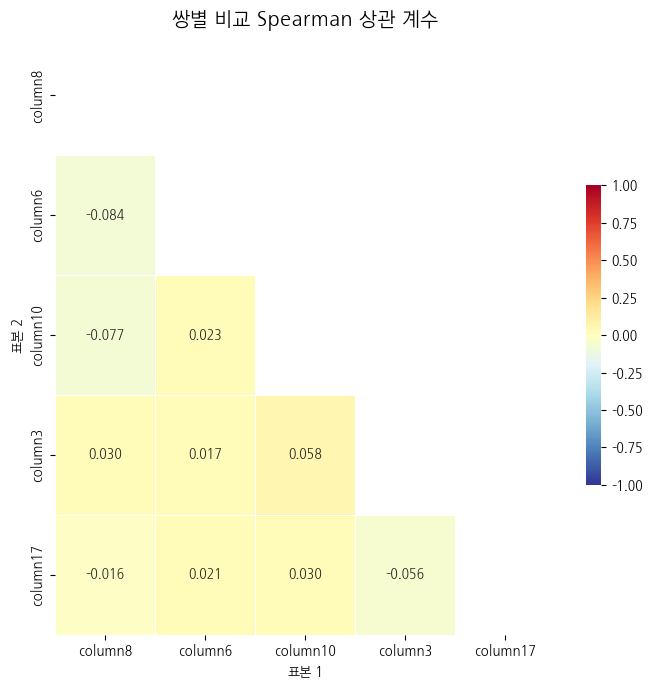

In [202]:
df_corr = df_sample.corr(method=corr_method)
mask = np.zeros_like(df_corr, dtype=np.bool)
mask[np.triu_indices_from(mask)] = True

fig, ax = plt.subplots(figsize=(7,7))
sns.heatmap(df_corr,
            cmap='RdYlBu_r',
            annot=True,
            mask=mask,
            fmt='.3f',
            linewidths=.5,
            cbar_kws={'shrink':.5},
            ax=ax,
            vmin=-1, vmax=1)
ax.set_title(f'쌍별 비교 {corr_method.capitalize()} 상관 계수',
             fontdict=dict(fontsize=15, fontweight='bold'))
ax.set_xlabel('표본 1', fontdict=dict(fontweight='bold'))
ax.set_ylabel('표본 2', fontdict=dict(fontweight='bold'))
fig.tight_layout()
plt.show()

In [151]:
df_sample.rename(columns={col:f'{col}(Rank)' for col in ordinals})

,column8,column2,column12,column10(Rank),column3(Rank)
0,3.884655,1592,46,5,1
1,1.513427,2634,194,2,5
2,1.039927,2615,153,6,1
3,2.666729,2241,62,0,5
4,2.401778,1864,33,0,4
...,...,...,...,...,...
495,0.333406,1958,185,5,0
496,0.596556,2890,127,3,4
497,0.221567,2302,124,4,3
498,1.333217,2358,67,3,6


In [153]:
'aaa'.endswith('a')

True

In [203]:
from matplotlib.ticker import FuncFormatter
import seaborn as sns
from eda_manager.chart.chart_helper import formatter_kmb, close_pyplot, save_chart_to_bytes

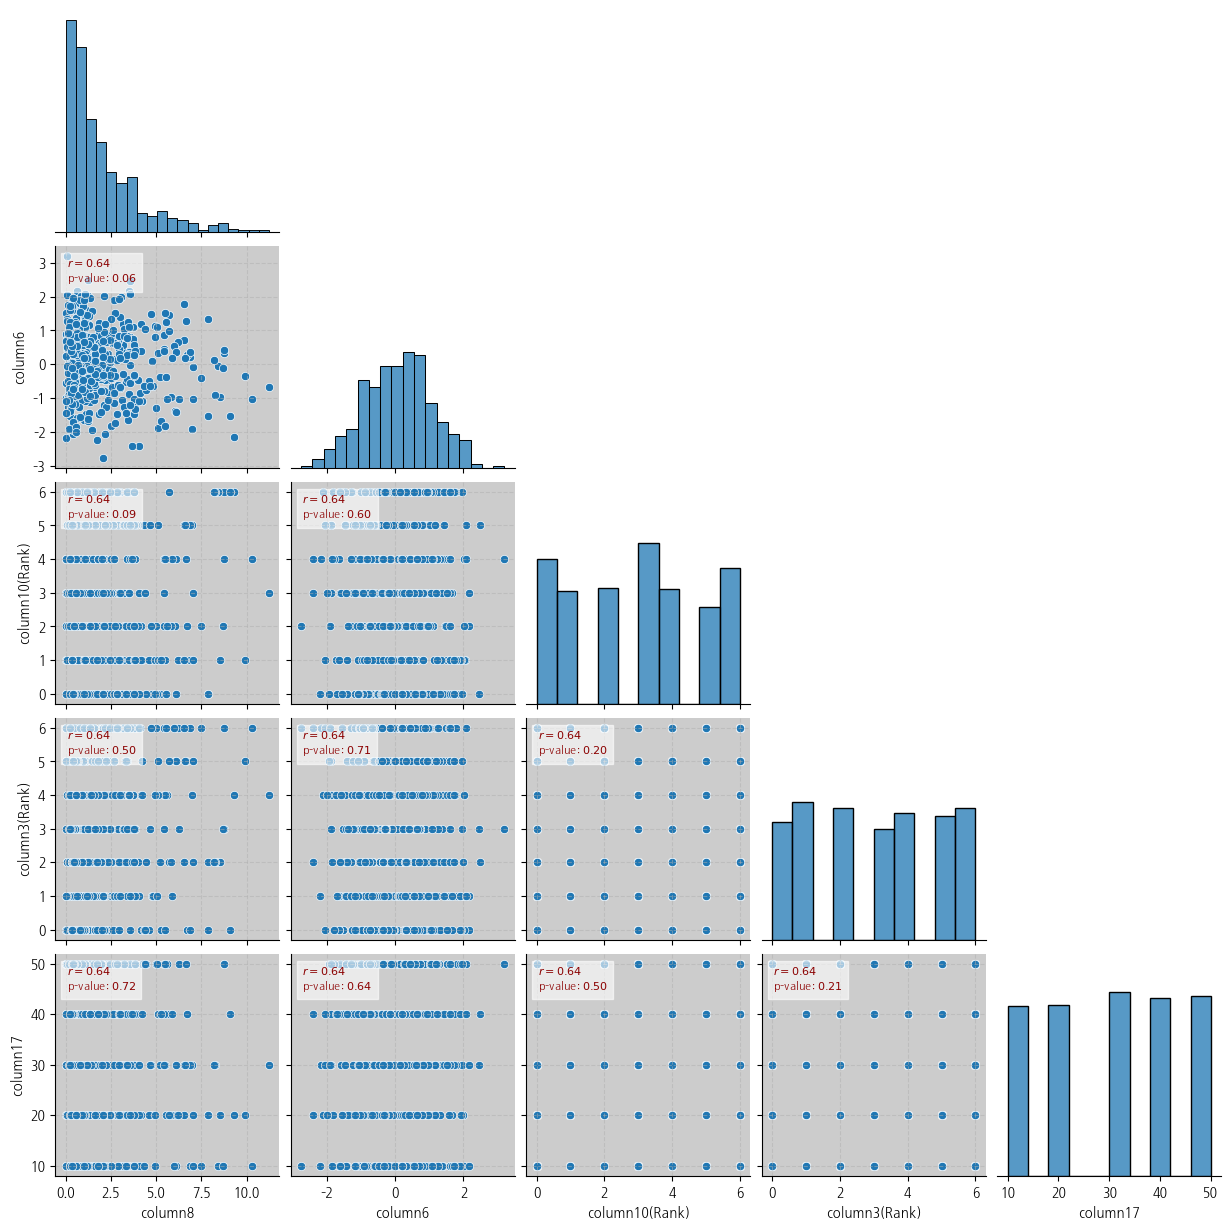

In [204]:
def overwrite_corr_value(x, y, ax=None, **kws):
    ax = ax or plt.gca()
    x_col_nm = x.name.split('(Rank)')[0] if x.name.endswith('(Rank)') else x.name
    y_col_nm = y.name.split('(Rank)')[0] if y.name.endswith('(Rank)') else y.name
    col = [col for col in corr_result if (col['Column1']==x_col_nm) and (col['Column2']==y_col_nm)][0]
    corr = col['Coefficient']
    p_val = col['PValue']
    ax.annotate(f'$r = {corr ** 2:.2f}$\np-value: ${p_val:.2f}$',
                xy=(.05, .95), xycoords=ax.transAxes, fontsize=8,
                color='darkred', backgroundcolor='#FFFFFF99', ha='left', va='top')
    if abs(corr)>=0.7:
        ax.set_facecolor('0.8')
    ax.grid(True, linestyle='--', alpha=0.5)
    min_val, max_val = ax.get_ylim()
    if max_val - min_val > 1_000:
        ax.yaxis.set_major_formatter(FuncFormatter(formatter_kmb))
    min_val, max_val = ax.get_xlim()
    if max_val - min_val > 1_000:
        ax.xaxis.set_major_formatter(FuncFormatter(formatter_kmb))

def overwrite_diag(x, ax=None, **kws):
    ax = ax or plt.gca()
    sns.histplot(x, ax=ax)
    ax.grid(True, linestyle='--', alpha=0.5)

g = sns.pairplot(df_sample.rename(columns={col:f'{col}(Rank)' for col in ordinals}),
                 corner=True)
g.map_lower(overwrite_corr_value)
# g.map_diag(sns.histplot)
g.savefig('test.png')